# 4. Model B: Siamese verifier

"Given R genuine reference signatures of the claimed writer, is this questioned signature a forgery?"

* **Model:** shared EfficientNet-B2 → 1408-d pooled features → 256-d embedding; pair features
  `[|e_r - e_q|, e_r * e_q]` → MLP → logit (questioned is forged)
* **Train:** pairs drawn on the fly from training writers only:
  (genuine_w, other genuine_w) → 0, (genuine_w, skilled forgery of w) → 1
* **Test:** per unseen writer, references = genuine #1..R; questioned = the other 24−R genuine + all 24 forgeries;
  score = mean logit over the R references. Threshold from the validation writers (EER point).

Saves `runs/siamese_fold<k>/`. Existing folds are loaded unless `RETRAIN = True` (≈ 25 min per fold).

In [1]:
FOLDS = [0, 1, 2, 3, 4]
EPOCHS = 12
PAIRS = 3000             # training pairs per epoch
BATCH = 12               # pairs per batch
LR = 1e-4
WEIGHT_DECAY = 0.05
N_REF = 5                # reference genuine signatures per writer
SEED = 42
RETRAIN = False

In [2]:
%run ./common.ipynb

In [3]:
import json
import time

import matplotlib.pyplot as plt


class PairTrainSet(Dataset):
    """Random balanced pairs from the given writers; regenerated every epoch."""

    def __init__(self, G, meta, idx, n_pairs):
        self.G, self.n = G, n_pairs
        m = meta.iloc[idx]
        self.gen = {w: g.index.values[g.label.values == 0] for w, g in m.groupby("writer")}
        self.forg = {w: g.index.values[g.label.values == 1] for w, g in m.groupby("writer")}
        self.writers = list(self.gen)

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        rng = np.random.default_rng()
        w = self.writers[rng.integers(len(self.writers))]
        ref, other = rng.choice(self.gen[w], 2, replace=False)
        label = int(rng.random() < 0.5)
        q = rng.choice(self.forg[w]) if label else other
        return (torch.from_numpy(to_input(np.asarray(self.G[ref]), rng)),
                torch.from_numpy(to_input(np.asarray(self.G[q]), rng)),
                torch.tensor(float(label)))


class Siamese(nn.Module):
    def __init__(self, pretrained=True, emb=256):
        super().__init__()
        b = build_model(pretrained)
        self.features, self.pool = b.features, b.avgpool
        self.proj = nn.Sequential(nn.Dropout(0.3), nn.Linear(1408, emb))
        self.head = nn.Sequential(nn.Linear(2 * emb, 128), nn.ReLU(inplace=True),
                                  nn.Dropout(0.3), nn.Linear(128, 1))

    def embed(self, x):
        return self.proj(torch.flatten(self.pool(self.features(x)), 1))

    def compare(self, er, eq):
        return self.head(torch.cat([(er - eq).abs(), er * eq], 1)).squeeze(1)

    def forward(self, xr, xq):
        return self.compare(self.embed(xr), self.embed(xq))


@torch.no_grad()
def siamese_score_writers(model, G, meta, idx, n_ref, device):
    """Embed every image once, then score each questioned signature against its
    writer's first n_ref genuine signatures. Returns (meta indices, labels, logits)."""
    model.eval()
    dl = ThreadLoader(SingleSet(G, idx), batch_size=32)
    embs = []
    for x in dl:
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            embs.append(model.embed(x.to(device)).float())
    E = dict(zip(idx, torch.cat(embs)))
    out_i, out_y, out_s = [], [], []
    m = meta.iloc[idx]
    for w, g in m.groupby("writer"):
        g = g.sort_values(["label", "index"])
        refs = g.index.values[(g.label.values == 0) & (g["index"].values <= n_ref)]
        quest = g.index.values[~((g.label.values == 0) & (g["index"].values <= n_ref))]
        er = torch.stack([E[r] for r in refs])                          # (R, d)
        for q in quest:
            eq = E[q].expand_as(er)
            out_s.append(model.compare(er, eq).float().mean().item())
            out_i.append(q)
            out_y.append(int(meta.label[q]))
    return np.array(out_i), np.array(out_y), np.array(out_s)

In [4]:
def train_siamese_fold(fold):
    name = f"siamese_fold{fold}"
    out = os.path.join(RUNS, name)
    os.makedirs(out, exist_ok=True)
    torch.manual_seed(SEED)
    device = DEVICE

    meta, tr, va, te = writer_split(fold=fold)
    G = load_gray("binary")
    print(f"[{name}] writers train {meta.writer[tr].nunique()} / val {meta.writer[va].nunique()} / "
          f"test {meta.writer[te].nunique()}  test writers {sorted(set(meta.writer[te]))}")

    dl_tr = ThreadLoader(PairTrainSet(G, meta, tr, PAIRS), batch_size=BATCH, shuffle=True, drop_last=True)
    model = Siamese().to(device)
    body = list(model.features.parameters())
    rest = list(model.proj.parameters()) + list(model.head.parameters())
    opt = torch.optim.AdamW([{"params": body, "lr": LR}, {"params": rest, "lr": LR * 10}],
                            weight_decay=WEIGHT_DECAY)
    sched = warmup_cosine(opt, len(dl_tr), EPOCHS * len(dl_tr))
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
    loss_fn = nn.BCEWithLogitsLoss()

    best_auc, hist = -1.0, []
    for ep in range(1, EPOCHS + 1):
        model.train()
        t0, run = time.time(), 0.0
        for xr, xq, yb in dl_tr:
            xr, xq, yb = xr.to(device), xq.to(device), yb.to(device)
            with torch.autocast(device.type, enabled=device.type == "cuda"):
                loss = loss_fn(model(xr, xq), yb * 0.9 + 0.05)          # label smoothing 0.1
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            run += loss.item()

        _, yv, sv = siamese_score_writers(model, G, meta, va, N_REF, device)
        thr, _ = eer_threshold(yv, sv)
        m = metrics(yv, sv, thr)
        hist.append({"epoch": ep, "train_loss": run / len(dl_tr), **{f"val_{k}": v for k, v in m.items()}})
        flag = ""
        if m["auc"] > best_auc:
            best_auc, flag = m["auc"], "  *"
            torch.save({"model": model.state_dict(), "thr": thr, "n_ref": N_REF}, os.path.join(out, "best.pt"))
        print(f"ep {ep:2d}  loss {hist[-1]['train_loss']:.4f}  val acc {m['acc']:.3f}  auc {m['auc']:.4f}  "
              f"eer {m['eer']:.3f}  ({time.time() - t0:.0f}s){flag}", flush=True)

    pd.DataFrame(hist).to_csv(os.path.join(out, "history.csv"), index=False)
    ck = torch.load(os.path.join(out, "best.pt"), map_location=device)
    model.load_state_dict(ck["model"])
    ti, yt, st = siamese_score_writers(model, G, meta, te, N_REF, device)
    res = {"name": name, "mode": "siamese", "fold": fold, "n_ref": N_REF, "best_val_auc": best_auc,
           "test": metrics(yt, st, ck["thr"]), "test_writers": sorted(int(w) for w in set(meta.writer[te]))}
    np.save(os.path.join(out, "test_scores.npy"), np.stack([ti, yt, st]))
    with open(os.path.join(out, "metrics.json"), "w") as f:
        json.dump(res, f, indent=2)
    return res

In [5]:
results = []
for fold in FOLDS:
    path = os.path.join(RUNS, f"siamese_fold{fold}", "metrics.json")
    if os.path.exists(path) and not RETRAIN:
        res = json.load(open(path))
        print(f"fold {fold}: loaded existing results")
    else:
        res = train_siamese_fold(fold)
    results.append({"fold": fold, **res["test"]})

df = pd.DataFrame(results).set_index("fold")[["auc", "eer", "acc", "far", "frr", "thr"]]
print(df.round(4))
d = df.drop(columns="thr")
print("\nmean +/- std (population std, as in summarize.ipynb):")
print(pd.DataFrame({"mean": d.mean(), "std": d.std(ddof=0)}).T.round(4))

fold 0: loaded existing results
fold 1: loaded existing results
fold 2: loaded existing results
fold 3: loaded existing results
fold 4: loaded existing results
         auc     eer     acc     far     frr     thr
fold                                                
0     0.7504  0.3379  0.6279  0.5795  0.1100  1.3225
1     0.6332  0.4017  0.6047  0.2311  0.6029 -0.0598
2     0.6449  0.4312  0.5708  0.4242  0.4354  0.0851
3     0.7009  0.3803  0.6279  0.3485  0.4019  0.1150
4     0.7807  0.2813  0.6977  0.2121  0.4163  0.7805

mean +/- std (population std, as in summarize.ipynb):
         auc     eer     acc     far     frr
mean  0.7020  0.3665  0.6258  0.3591  0.3933
std   0.0575  0.0523  0.0416  0.1349  0.1591


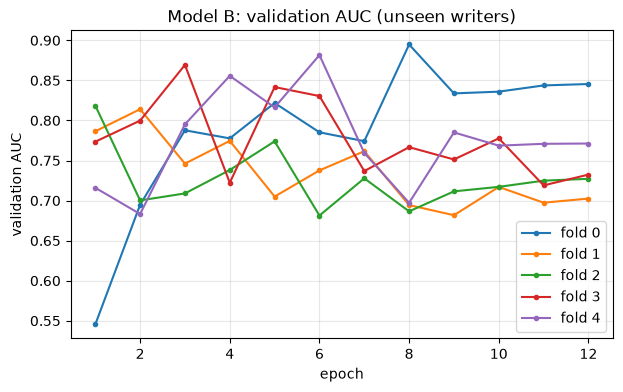

In [6]:
plt.figure(figsize=(7, 4))
for fold in FOLDS:
    h = pd.read_csv(os.path.join(RUNS, f"siamese_fold{fold}", "history.csv"))
    plt.plot(h.epoch, h.val_auc, marker=".", label=f"fold {fold}")
plt.xlabel("epoch"); plt.ylabel("validation AUC"); plt.title("Model B: validation AUC (unseen writers)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()